In [2]:
import pandas as pd

df_iris = pd.read_csv('IRIS.csv')
df_iris.head(10)

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


In [4]:
df_iris.drop('species', axis=1).corr()

,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000000,-0.109369,0.871754,0.817954
sepal_width,-0.109369,1.000000,-0.420516,-0.356544
petal_length,0.871754,-0.420516,1.000000,0.962757
petal_width,0.817954,-0.356544,0.962757,1.000000


In [7]:
from sklearn.svm import SVC
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

le = LabelEncoder()

In [8]:
df_iris['species_encoded'] = le.fit_transform(df_iris['species'])

x = df_iris[['petal_length', 'petal_width']]
y = df_iris['species_encoded']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [25]:
# using linear (93%, 100%) or rbf (93%, 100%) causes same separation
model = SVC(kernel='linear', C=0.1)
#model = SVC(kernel='rbf', C=0.1, gamma=10) 
model.fit(x_train, y_train)

print(f"Training Accuracy: {model.score(x_train, y_train):.2%}")
print(f"Testing Accuracy: {model.score(x_test, y_test):.2%}")

Training Accuracy: 95.00%
Testing Accuracy: 100.00%


C:\Users\malli\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\base.py:465: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


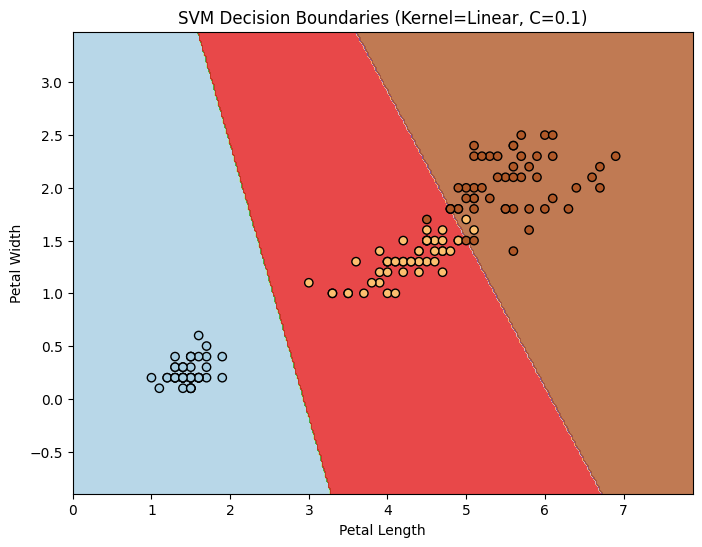

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Create a mesh grid to plot in
h = .02  # step size in the mesh
x_min, x_max = x.iloc[:, 0].min() - 1, x.iloc[:, 0].max() + 1
y_min, y_max = x.iloc[:, 1].min() - 1, x.iloc[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))

# Predict across the entire mesh grid
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.8)

# Plot the original training points
plt.scatter(x.iloc[:, 0], x.iloc[:, 1], c=y, edgecolors='k', cmap=plt.cm.Paired)
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.title(f'SVM Decision Boundaries (Kernel=Linear, C={model.C})')
plt.show()

In [30]:
from sklearn import datasets
cancer = datasets.load_breast_cancer()

df_small = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df_small.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [32]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x = scaler.fit_transform(df_small)
y = cancer.target

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [35]:
# using linear (98%, 98%)
model = SVC(kernel='linear', C=0.1)
model.fit(x_train, y_train)

print(f"Training Accuracy: {model.score(x_train, y_train):.2%}")
print(f"Testing Accuracy: {model.score(x_test, y_test):.2%}")

Training Accuracy: 98.24%
Testing Accuracy: 98.25%


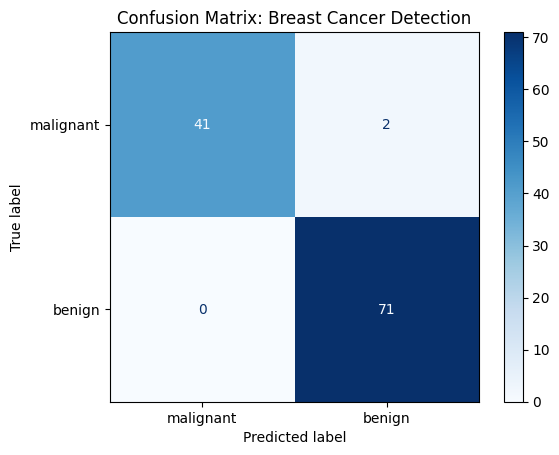

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate predictions for the test set
y_pred = model.predict(x_test)

# Create the matrix
cm = confusion_matrix(y_test, y_pred)

# Plot it nicely
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix: Breast Cancer Detection")
plt.show()

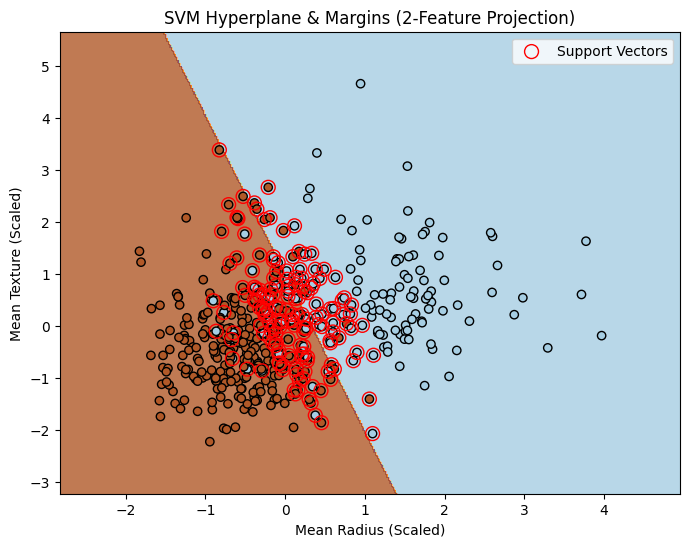

In [37]:
# We'll pick 'mean radius' and 'mean texture' (Indices 0 and 1)
X_mini = x_train[:, :2] 
model_mini = SVC(kernel='linear', C=0.1)
model_mini.fit(X_mini, y_train)

# Create a mesh to plot in
h = .02
x_min, x_max = X_mini[:, 0].min() - 1, X_mini[:, 0].max() + 1
y_min, y_max = X_mini[:, 1].min() - 1, X_mini[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predict and plot
Z = model_mini.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.8)
plt.scatter(X_mini[:, 0], X_mini[:, 1], c=y_train, edgecolors='k', cmap=plt.cm.Paired)

# Highlight the Support Vectors (the points defining the hyperplane)
plt.scatter(model_mini.support_vectors_[:, 0], model_mini.support_vectors_[:, 1], 
            s=100, facecolors='none', edgecolors='r', label='Support Vectors')

plt.xlabel('Mean Radius (Scaled)')
plt.ylabel('Mean Texture (Scaled)')
plt.title('SVM Hyperplane & Margins (2-Feature Projection)')
plt.legend()
plt.show()

In [38]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=0)
grid.fit(x_train, y_train)

print(f"Best Parameters: {grid.best_params_}")
print(f"New RBF Accuracy: {grid.best_score_:.2%}")

Best Parameters: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
New RBF Accuracy: 97.36%


In [39]:
model = SVC(kernel='rbf', C=10, gamma=0.01)
model.fit(x_train, y_train)

print(f"Training Accuracy: {model.score(x_train, y_train):.2%}")
print(f"Testing Accuracy: {model.score(x_test, y_test):.2%}")

Training Accuracy: 99.12%
Testing Accuracy: 98.25%


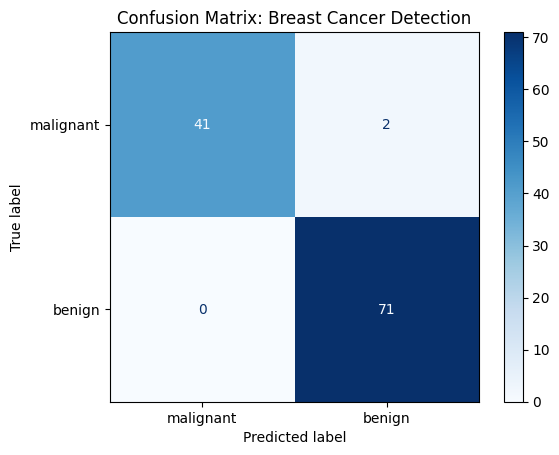

In [40]:
# Generate predictions for the test set
y_pred = model.predict(x_test)

# Create the matrix
cm = confusion_matrix(y_test, y_pred)

# Plot it nicely
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=cancer.target_names)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix: Breast Cancer Detection")
plt.show()

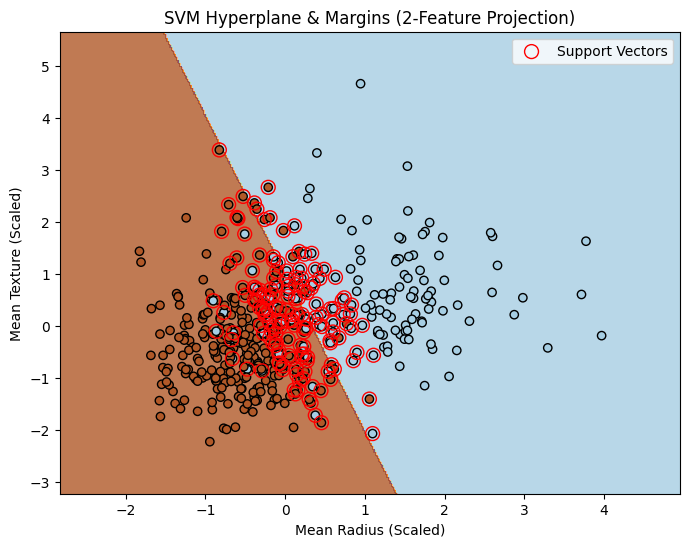

In [41]:
# We'll pick 'mean radius' and 'mean texture' (Indices 0 and 1)
X_mini = x_train[:, :2] 
model_mini = SVC(kernel='linear', C=0.1)
model_mini.fit(X_mini, y_train)

# Create a mesh to plot in
h = .02
x_min, x_max = X_mini[:, 0].min() - 1, X_mini[:, 0].max() + 1
y_min, y_max = X_mini[:, 1].min() - 1, X_mini[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predict and plot
Z = model_mini.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap=plt.cm.Paired, alpha=0.8)
plt.scatter(X_mini[:, 0], X_mini[:, 1], c=y_train, edgecolors='k', cmap=plt.cm.Paired)

# Highlight the Support Vectors (the points defining the hyperplane)
plt.scatter(model_mini.support_vectors_[:, 0], model_mini.support_vectors_[:, 1], 
            s=100, facecolors='none', edgecolors='r', label='Support Vectors')

plt.xlabel('Mean Radius (Scaled)')
plt.ylabel('Mean Texture (Scaled)')
plt.title('SVM Hyperplane & Margins (2-Feature Projection)')
plt.legend()
plt.show()

In [9]:
import pandas as pd

df_med = pd.read_csv('Social_Network_Ads.csv')
df_med

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
if 'Gender' in df_med.columns:
    df_med['gender_encoded'] = le.fit_transform(df_med['Gender'])
    df_med = df_med.drop(['Gender', 'User ID'], axis=1)

df_med.corr()

,Age,EstimatedSalary,Purchased,gender_encoded
Age,1.000000,0.155238,0.622454,-0.073741
EstimatedSalary,0.155238,1.000000,0.362083,-0.060435
Purchased,0.622454,0.362083,1.000000,-0.042469
gender_encoded,-0.073741,-0.060435,-0.042469,1.000000


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()

x = ss.fit_transform(df_med[['Age', 'EstimatedSalary']])
y = df_med['Purchased']

x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

In [15]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=0)
grid.fit(x_train, y_train)

print(f"Best Parameters: {grid.best_params_}")
print(f"New RBF Accuracy: {grid.best_score_:.2%}")

Best Parameters: {'C': 0.1, 'gamma': 1, 'kernel': 'rbf'}
New RBF Accuracy: 90.62%


In [19]:
model = SVC(kernel='linear')
model.fit(x_train, y_train)

print(f"Linear Accuracy: {model.score(x_test, y_test):.2%}")

Linear Accuracy: 86.25%


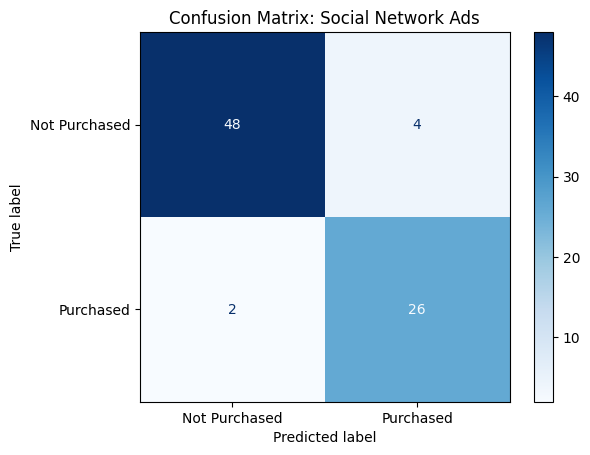

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
# Generate predictions for the test set
y_pred = model.predict(x_test)

# Create the matrix
cm = confusion_matrix(y_test, y_pred)

# Plot it nicely
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels= ['Not Purchased', 'Purchased'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix: Social Network Ads")
plt.show()

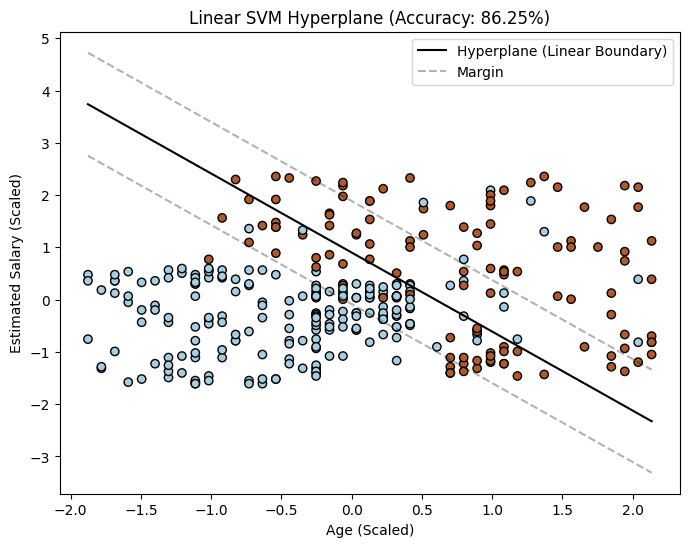

In [30]:
import numpy as np
# 1. Train the Linear Model (Assuming X_train is scaled)
linear_model = SVC(kernel='linear', C=1.0)
linear_model.fit(x_train, y_train)

# 2. Get the hyperplane parameters
w = linear_model.coef_[0]
b = linear_model.intercept_[0]

# 3. Create the line equation: x2 = -(w1/w2) * x1 - (b/w2)
x_visual = np.linspace(x_train[:, 0].min(), x_train[:, 0].max(), 10)
y_visual = -(w[0] / w[1]) * x_visual - (b / w[1])

# 4. Plotting
plt.figure(figsize=(8, 6))
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, cmap='Paired', edgecolors='k')
plt.plot(x_visual, y_visual, 'k-', label='Hyperplane (Linear Boundary)')

# Optional: Plot the margins (gutters)
margin = 1 / np.sqrt(np.sum(linear_model.coef_ ** 2))
y_neg = y_visual - np.sqrt(1 + (w[0]/w[1])**2) * margin
y_pos = y_visual + np.sqrt(1 + (w[0]/w[1])**2) * margin
plt.plot(x_visual, y_neg, 'k--', alpha=0.3, label='Margin')
plt.plot(x_visual, y_pos, 'k--', alpha=0.3)

plt.xlabel('Age (Scaled)')
plt.ylabel('Estimated Salary (Scaled)')
plt.title(f'Linear SVM Hyperplane (Accuracy: {linear_model.score(x_test, y_test):.2%})')
plt.legend()
plt.show()

In [25]:
model = SVC(kernel='rbf', C=0.1, gamma=1)
model.fit(x_train, y_train)

print(f"RBF Accuracy: {model.score(x_test, y_test):.2%}")

RBF Accuracy: 92.50%


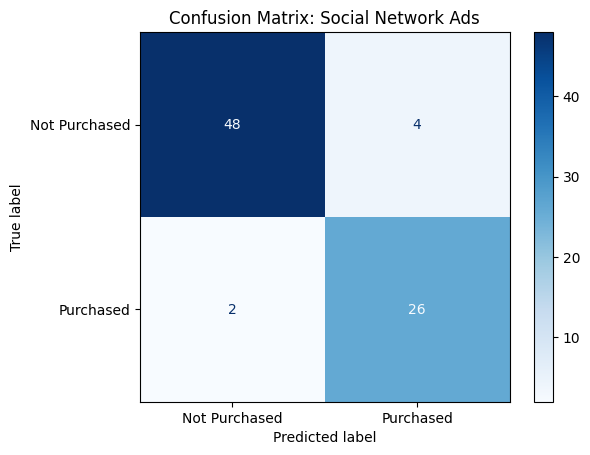

In [26]:
# Generate predictions for the test set
y_pred = model.predict(x_test)

# Create the matrix
cm = confusion_matrix(y_test, y_pred)

# Plot it nicely
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels= ['Not Purchased', 'Purchased'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix: Social Network Ads")
plt.show()

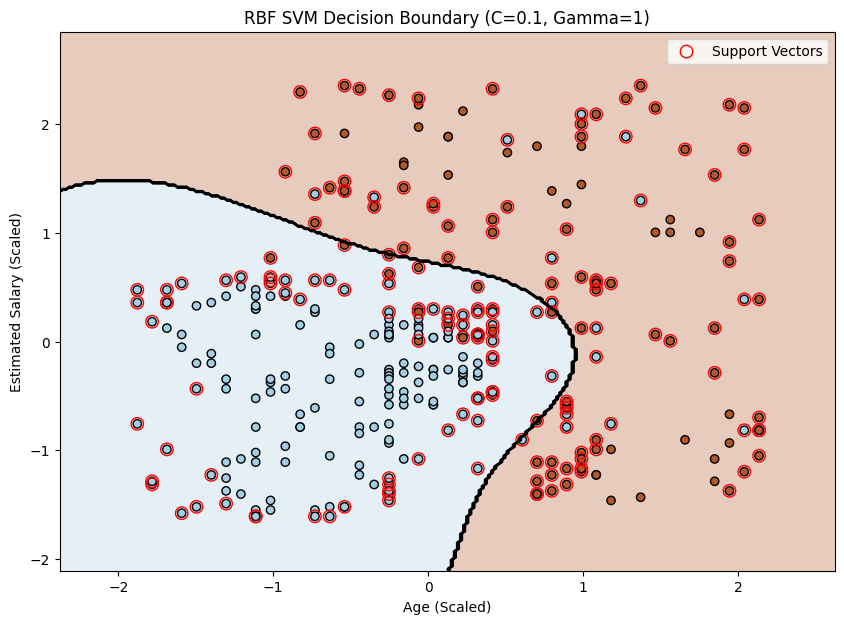

In [32]:
# 1. Define the boundaries for the plot based on your scaled features
# We use x_train because you've already scaled it
x_min, x_max = x_train[:, 0].min() - 0.5, x_train[:, 0].max() + 0.5
y_min, y_max = x_train[:, 1].min() - 0.5, x_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# 2. Predict over the mesh grid to find the decision regions
# 'model' is your SVC with kernel='rbf'
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# 3. Plot the decision boundary
plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='Paired') # The "regions"
plt.contour(xx, yy, Z, colors='k', linewidths=1)  # The actual "hyperplane" boundary line

# 4. Plot the training points
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, edgecolors='k', cmap='Paired')

# 5. Highlight the Support Vectors (The points that define the curve)
plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], 
            s=80, facecolors='none', edgecolors='r', label='Support Vectors')

plt.xlabel('Age (Scaled)')
plt.ylabel('Estimated Salary (Scaled)')
plt.title(f'RBF SVM Decision Boundary (C={model.C}, Gamma={model.gamma})')
plt.legend()
plt.show()

In [3]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

mnist = fetch_openml('mnist_784', version=1, as_frame=False)

# X contains 70,000 images, each with 784 pixels (28x28)
# y contains the labels (0-9)
x, y = mnist["data"], mnist["target"]

C:\Users\malli\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\datasets\_openml.py:1022: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [4]:
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=10000, test_size=2000, random_state=42)

# Important: Scale the pixel values (0-255) to (0-1)
x_train = x_train / 255.0
x_test = x_test / 255.0
print(f"Training shape: {x_train.shape}")

Training shape: (10000, 784)


In [39]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

grid = GridSearchCV(SVC(), param_grid, refit=True, verbose=0)
grid.fit(x_train, y_train)

print(f"Best Parameters: {grid.best_params_}")
print(f"New RBF Accuracy: {grid.best_score_:.2%}")

Best Parameters: {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
New RBF Accuracy: 96.14%


In [5]:
from sklearn.svm import SVC

model = SVC(kernel='rbf', C=10, gamma=0.01)
model.fit(x_train, y_train)

print(f"RBF Accuracy: {model.score(x_test, y_test):.2%}")

RBF Accuracy: 96.20%


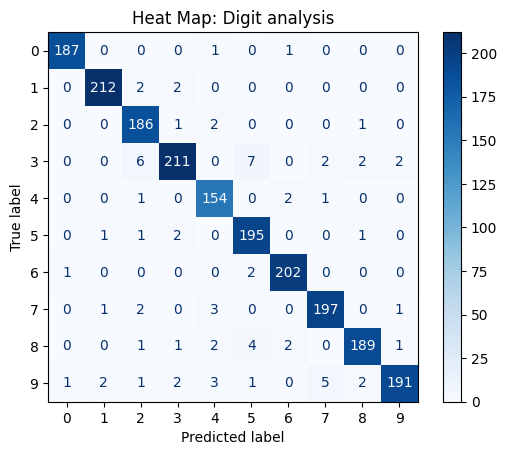

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Generate predictions for the test set
y_pred = model.predict(x_test)

# Create the matrix
cm = confusion_matrix(y_test, y_pred)

# Plot it nicely
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y_test))
disp.plot(cmap='Blues')
plt.title("Heat Map: Digit analysis")
plt.show()